# Домашнє завдання 4: три прості діаграми й висновки

Ім’я: Kantemyr Iryna

Збережіть цей файл як **lesson4_homework.ipynb** (File → Save As). Заповнюйте клітинки по черзі. Наприкінці запустіть усе: **Run All**.

Дані навчальні (вигадані). Можна взяти свій набір даних із домашнього завдання 3.

## Крок 1. Запитання

Одне речення: яке запитання ви ставите й для кого.

Приклад: «Яка точка продає більше кави? Для власниці кав’ярні».

**Моє запитання:** Який заклад має більше харчових відходів. Для власника великого бізнесу.

### Дані
Запустіть клітинку: вона створює таблиці `sales` (продажі) і `prices` (ціни). Якщо берете свої дані — замініть код на `df = pd.read_csv("ваш_файл.csv")`.

In [16]:
import pandas as pd
import numpy as np

df=pd.read_csv('1_food_waste/food_waste_dataset.csv', parse_dates=['Date'])

print(df.shape)



(8000, 16)


Дивлюсь які є категорії, де є пропуски, важливі для мене клитинки з пропусками чи ні (ні), 

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Inventory_ID         8000 non-null   str           
 1   Date                 8000 non-null   datetime64[us]
 2   Business_Type        8000 non-null   str           
 3   Food_Category        8000 non-null   str           
 4   Purchase_Quantity    8000 non-null   int64         
 5   Units_Sold           8000 non-null   int64         
 6   Remaining_Stock      8000 non-null   int64         
 7   Shelf_Life_Days      7765 non-null   float64       
 8   Storage_Temperature  7814 non-null   float64       
 9   Daily_Demand         7790 non-null   float64       
 10  Promotion            8000 non-null   str           
 11  Weather              7797 non-null   str           
 12  Waste_Quantity       8000 non-null   int64         
 13  Waste_Reason         8000 non-null   str    

In [18]:
df.head(20)

,Inventory_ID,Date,Business_Type,Food_Category,Purchase_Quantity,Units_Sold,Remaining_Stock,Shelf_Life_Days,Storage_Temperature,Daily_Demand,Promotion,Weather,Waste_Quantity,Waste_Reason,Donation_Made,Waste_Level
0,INV000001,2025-01-01,Restaurant,Bakery,77,77,0,4.0,20.4,77.0,No,Sunny,0,No Waste,No,Low
1,INV000002,2025-01-01,Cafeteria,Bakery,75,53,22,3.0,22.8,53.0,No,Cloudy,6,Low Demand,No,Medium
2,INV000003,2025-01-01,Supermarket,Fruits,176,159,17,6.0,12.4,159.0,No,Sunny,4,Expired,No,Medium
3,INV000004,2025-01-01,Cafeteria,Dairy,58,58,0,7.0,3.5,83.0,Yes,Cloudy,0,No Waste,No,Low
4,INV000005,2025-01-01,Restaurant,Fruits,85,85,0,3.0,3.3,87.0,No,Hot,0,No Waste,No,Low
5,INV000006,2025-01-01,Supermarket,Bakery,138,138,0,3.0,17.0,183.0,Yes,Rainy,0,No Waste,No,Low
6,INV000007,2025-01-01,Supermarket,Vegetables,178,145,33,7.0,4.0,145.0,No,Cloudy,4,Overproduction,No,Medium
7,INV000008,2025-01-01,Restaurant,Dairy,105,94,11,8.0,5.9,94.0,No,Sunny,1,Storage Issue,No,Low
8,INV000009,2025-01-01,Cafeteria,Prepared Food,71,54,17,2.0,16.0,54.0,No,Sunny,4,Expired,No,Medium
9,INV000010,2025-01-01,Restaurant,Bakery,106,106,0,3.0,23.6,129.0,Yes,Sunny,0,No Waste,No,Low


Далі передивляюсь скільки унікальних значень в кожній категорії, щоб визначитися з якими категоріями я буду працювати.

In [19]:
df.nunique()

Inventory_ID           8000
Date                    365
Business_Type             4
Food_Category             6
Purchase_Quantity       296
Units_Sold              213
Remaining_Stock         204
Shelf_Life_Days          14
Storage_Temperature     367
Daily_Demand            250
Promotion                 2
Weather                   4
Waste_Quantity          115
Waste_Reason              5
Donation_Made             2
Waste_Level               3
dtype: int64

In [20]:
#Обрала ці дві категорії, буду їх розглядати відносно категорії Remaining_Stock - кількості залишку їжі
print(df['Business_Type'].unique().tolist())
print(df['Food_Category'].unique().tolist())

['Restaurant', 'Cafeteria', 'Supermarket', 'Cloud Kitchen']
['Bakery', 'Fruits', 'Dairy', 'Vegetables', 'Prepared Food', 'Meat']


## Крок 2. Цифри

Порахуйте `groupby` (суми або середні за групами) і `describe()` для однієї числової колонки.

Підказка: `sales.groupby("shop")["cups"].sum()` і `sales["cups"].describe()`

In [21]:
# За рік отримали таку кількість відходів по типам заклададів
print(df.groupby('Business_Type')['Waste_Quantity'].sum())


Business_Type
Cafeteria         5125
Cloud Kitchen     8662
Restaurant       11144
Supermarket      21248
Name: Waste_Quantity, dtype: int64


In [22]:
#Побудували табл. відходів по типам закладів, категорій продуктів, з вказанням суми відходів та середнього
print(df.groupby(['Business_Type','Food_Category'])['Waste_Quantity'].agg(["sum", "mean"]).round(1))

                              sum  mean
Business_Type Food_Category            
Cafeteria     Bakery          983   4.1
              Dairy           630   2.7
              Fruits          740   2.6
              Meat            662   2.7
              Prepared Food  1373   4.7
              Vegetables      737   2.7
Cloud Kitchen Bakery         1343   5.1
              Dairy          1056   4.7
              Fruits         1242   4.5
              Meat           1016   4.3
              Prepared Food  2882   9.8
              Vegetables     1123   4.1
Restaurant    Bakery         1897   5.0
              Dairy          1118   3.2
              Fruits         1817   4.2
              Meat           1660   4.4
              Prepared Food  3135   6.7
              Vegetables     1517   3.5
Supermarket   Bakery         2832   7.8
              Dairy          2497   7.1
              Fruits         3324   7.6
              Meat           3316   8.5
              Prepared Food  5972  14.2


In [23]:
#Відобразила перевернуту таблицю для зручності перегляду
pivot = df.pivot_table(index='Food_Category', columns='Business_Type', values='Waste_Quantity', aggfunc='sum' )
pivot

Business_Type,Cafeteria,Cloud Kitchen,Restaurant,Supermarket
Food_Category,,,,
Bakery,983,1343,1897,2832
Dairy,630,1056,1118,2497
Fruits,740,1242,1817,3324
Meat,662,1016,1660,3316
Prepared Food,1373,2882,3135,5972
Vegetables,737,1123,1517,3307


In [24]:
#створюю таблицю тільки з тими даними якими я працюю
waste_summary = df[['Business_Type','Food_Category','Waste_Quantity']]

#бачимо великий максимум
waste_summary.describe()


,Waste_Quantity
count,8000.000000
mean,5.772375
std,16.450741
min,0.000000
25%,0.000000
50%,1.000000
75%,7.000000
max,447.000000


Використовуючи ШІ перебрала кількість значень більше 100, 200, 300, 400. На мою думку такий максимум не помилка набору, а викиди можливі

In [25]:

count_above = (df['Waste_Quantity'] > 300).sum()
pct_above = (df['Waste_Quantity'] > 300).mean() * 100


print(f"Кількість значень: {count_above} ({pct_above:.2f}%)")

Кількість значень: 3 (0.04%)


## Крок 3. Три діаграми

У кожної — назва (`plt.title`) і підписи осей (`plt.xlabel`, `plt.ylabel`). 1–3 кольори, без зайвих прикрас.

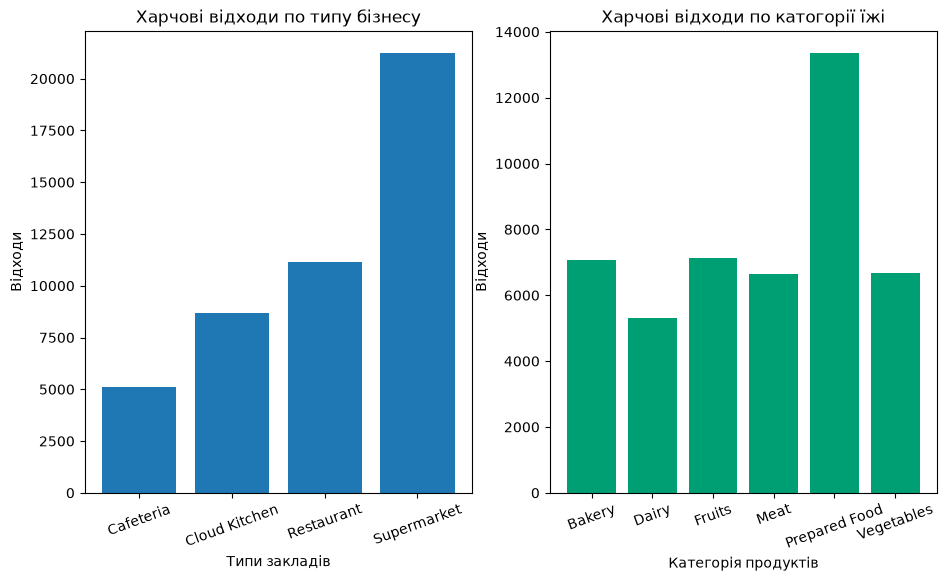

In [26]:
import matplotlib.pyplot as plt

# Діаграма 1: стовпчики — порівняння груп (вісь від нуля)
ig, axes = plt.subplots(1, 2, figsize=(11, 6))
waste_by_business=waste_summary.groupby('Business_Type')['Waste_Quantity'].sum()
waste_by_category=waste_summary.groupby('Food_Category')['Waste_Quantity'].sum()

axes[0].bar(waste_by_business.index, waste_by_business.values)
axes[0].set_title("Харчові відходи по типу бізнесу")
axes[0].set_xlabel('Типи закладів')
axes[0].set_ylabel('Відходи')
axes[0].tick_params(axis='x', rotation=20)

axes[1].bar(waste_by_category.index, waste_by_category.values, color="#009E73")
axes[1].set_title("Харчові відходи по катогорії їжі")
axes[1].tick_params(axis='x', rotation=20)
axes[1].set_ylabel('Відходи')
axes[1].set_xlabel('Категорія продуктів')

#waste_summary.bar([][])
plt.show()


**Крок 4 — висновок 1 (одне речення):** Найбільша кількість відходів у супермаркетах - більше 20000, що майже вдвічі більше за попередній тип закладу Рестарани.

Найбільша кількість відходів від категорії Prepared Food – більше 13000, значення з великим відривом від попереднього типу Fruits/


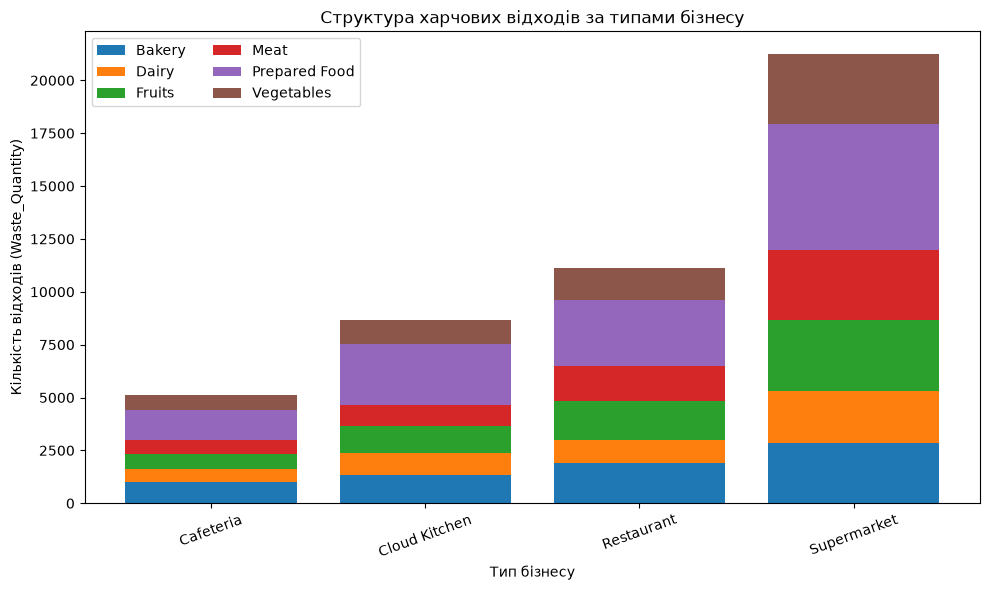

In [27]:
# Використовую ШІ
# Разворачиваем вашу таблицу pivot: строки — 4 типа бизнеса, столбцы — 6 категорий еды
data = pivot.T

plt.figure(figsize=(10, 6))

# Создаём «дно» из нулей для 4 столбиков (по одному нулю на каждый тип бизнеса)
bottom = np.zeros(len(data))

# Цикл сам пройдёт по всем 6 категориям еды и поставит их друг на друга
for category in data.columns:
    plt.bar(data.index, data[category], bottom=bottom, label=category)
    bottom += data[category].values  # поднимаем «дно» на высоту добавленного слоя

plt.title("Структура харчових відходів за типами бізнесу")
plt.xlabel("Тип бізнесу")
plt.ylabel("Кількість відходів (Waste_Quantity)")
plt.xticks(rotation=20)
plt.legend(ncol=2, loc="upper left")
plt.tight_layout()
plt.show()

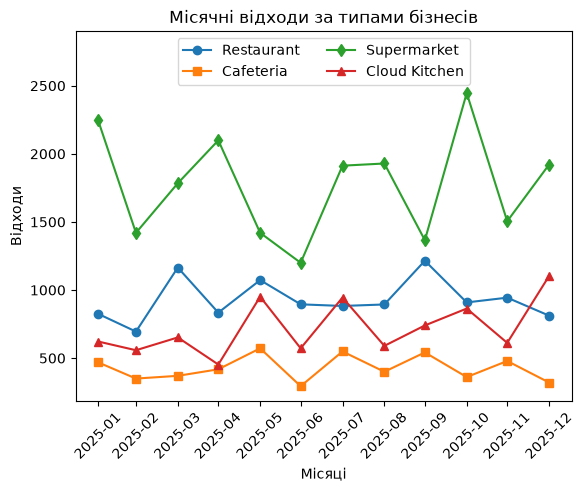

In [28]:
# Діаграма 2: лінія (зміна в часі) або гістограма (розподіл)
bus_types = df['Business_Type'].unique().tolist()
monthly = (df.groupby([pd.Grouper(key='Date', freq='ME'), 'Business_Type'])['Waste_Quantity'].sum().reset_index())

for t, m in zip(bus_types, "osd^"):
    part=monthly[monthly['Business_Type']==t]
    plt.plot(part['Date'], part['Waste_Quantity'], marker=m, label=t)
plt.title("Місячні відходи за типами бізнесів")
plt.ylabel("Відходи")
plt.xlabel("Місяці")
plt.legend(ncol=2, loc="upper center")
plt.ylim(top=2900)


# Використання ШІ 3 рядка
# Принудительно ставим все 12 дат и задаём формат ГГГГ-ММ
dates = sorted(monthly['Date'].unique())
plt.xticks(dates, [d.strftime('%Y-%m') for d in dates], rotation=45)

plt.show()

**Крок 4 — висновок 2 (одне речення):** Візуально бачимо, що немає залежності відходів за категоріями від місяців

In [29]:
# Діаграма 3: scatter — зв’язок двох чисел
wide = df.pivot_table(index="Date", columns="Business_Type",
                        values="Waste_Quantity", aggfunc="sum")
print(round(wide["Restaurant"].corr(wide["Cafeteria"]), 2))
print(round(wide["Restaurant"].corr(wide["Cloud Kitchen"]), 2))
print(round(wide["Restaurant"].corr(wide["Supermarket"]), 2))
print(round(wide["Cloud Kitchen"].corr(wide["Cafeteria"]), 2))
print(round(wide["Supermarket"].corr(wide["Cafeteria"]), 2))
print(round(wide["Supermarket"].corr(wide["Cloud Kitchen"]), 2))


wide
#кореляція повністю відсутня

0.01
-0.04
0.02
0.0
-0.0
0.06


Business_Type,Cafeteria,Cloud Kitchen,Restaurant,Supermarket
Date,,,,
2025-01-01,22.0,18.0,1.0,17.0
2025-01-02,46.0,20.0,33.0,125.0
2025-01-03,3.0,15.0,13.0,109.0
2025-01-04,0.0,23.0,12.0,1.0
2025-01-05,7.0,38.0,44.0,32.0
...,...,...,...,...
2025-12-27,60.0,51.0,64.0,39.0
2025-12-28,0.0,8.0,37.0,15.0
2025-12-29,NaN,36.0,2.0,26.0


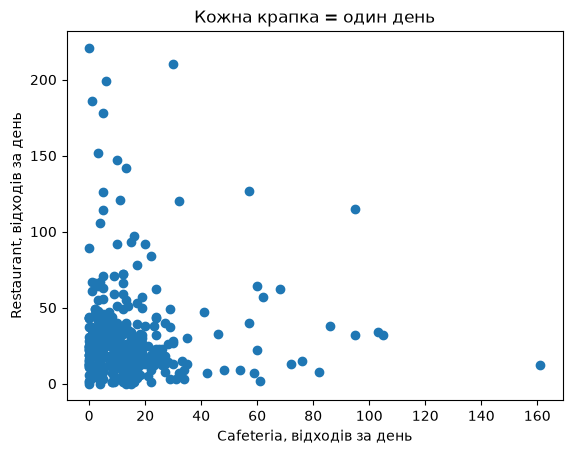

In [30]:
# Діаграма 3: scatter — зв’язок двох чисел
x,y = wide['Cafeteria'],wide[ 'Restaurant']
plt.scatter(x,y)
plt.xlabel("Cafeteria, відходів за день")
plt.ylabel("Restaurant, відходів за день")
plt.title("Кожна крапка = один день")
plt.show()

**Крок 4 — висновок 3 (одне речення):** Кореляція дорівнює 0, ніякої закономірності не виявлено, максимальні значення відходів не співпадає

## Крок 5. Перевірка однієї діаграми

Яку діаграму перевірили: "Структура харчових відходів за типами бізнесу" Диаграма за пункту 1.

- [V] вісь стовпчиків починається від нуля
- [V] є назва й підписи осей
- [V] зрозуміло без пояснень

## AI (за бажанням)

Мій запит: У мене завдання перевірити одну з моїх діаграм. Я надала тобі скрини. Питання: Перевірити діаграму:
1. Вісь стовпчиків починається від нуля? 
2. Є назва і підписи осей? 
3. Зрозуміле без пояснень? Надай мені рекомендацію по відповіді.

Що відповів AI: 
1.Надал рекомендації по переіменуванню однієї діаграми - "Структура харчових відходів за типами бізнесу"
2. Підготував розгорнуту відповідь

Як я перевірила: Візуально оцінив у мене вийшли такіж висновки

Не вставляйте в чат особисті дані, паролі чи ключі. Не буду

## Крок 6. Перед здачею

Kernel → Restart → **Run All**. Перевірте, що всі три діаграми видно. Здайте файл у Moodle або через Git (див. текст завдання).